In [1258]:
import pandas as pd
import numpy as np
import math
from PIL import Image

In [1259]:
img = np.asarray(Image.open("chelovechki/1.png").convert("L")) / float(255.0)
print(img)

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 1. 1. 0. 0.]
 [0. 1. 1. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


In [1260]:
df = pd.DataFrame({
    'y' : [0] * 0,
    'et': [0] * 0,
    'er': [0] * 0
})

print(df)



Empty DataFrame
Columns: [y, et, er]
Index: []


In [1261]:
def sigma(x):
  res = 0
  if x > 700:
    res = 1
  elif x < -700:
    res = 0
  else: 
    res = 1 / (1 + math.exp(-x))
  return res
def porog(x):
  res = 0
  if x >= 0:
    res = 1
  return res

neironcount = 0

class akson:
  def __init__(self):
    self.wes = 0
  def __repr__(self):
    return str(self.wes)

class neiron:
  def __init__(self):
      global neironcount
      self.aksons = []
      self.neirons = []
      self.id = neironcount
      neironcount += 1
      self.lastvalue = 0
  def getvalue(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

class inputneiron(neiron):
  def setvalue(self, x):
    self.myvalue = x
  def getvalue(self):
    #print(f"в нейроне {self.id} значение {self.myvalue} x")
    self.lastvalue = self.myvalue
    return self.myvalue
  def __init__(self):
    super().__init__()
    self.myvalue = 0

class outputneiron(neiron):
  def getvalue(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

In [1262]:
import random

layer1 = [inputneiron() for i in range(36)]
layer2 = [neiron() for i in range(6)]
layer3 = outputneiron()
biasneiron = inputneiron()
biasneiron.setvalue(1)
neironsall = layer1 + layer2 + [layer3]
aksonsall = []

layer1.append(biasneiron)
layer2.append(biasneiron)
layer3.neirons.append(biasneiron)

for n in layer2:
  n.neirons = layer1
  for j in range(len(layer1)):
    n.aksons.append(akson())

layer3.neirons = layer2
for j in range(len(layer2)):
  layer3.aksons.append(akson())

for n in neironsall:
  for a in n.aksons:
    a.wes = random.uniform(-1, 1)
    aksonsall.append(a)

for a in aksonsall:
  a.wes = random.uniform(-1, 1)

In [1263]:
def showwesa():
  for a in aksonsall:
    print(a.wes)
#print(aksonsall)
showwesa()
print(aksonsall)

0.4586778403952112
-0.5474268005848391
0.16029084953503214
0.22109335858317114
-0.9560936051026743
0.5743466892877718
-0.5857660604495356
0.3736901795686207
0.29494062529838483
-0.05371398669722649
-0.6926562678547981
-0.0780638147602839
0.855732504090571
-0.7087090600477055
-0.2127328645553379
-0.432176069779556
-0.4638615117141853
0.7156988763185763
0.5003987586257466
0.00844163022087252
-0.17812382602656052
0.8675108078508604
0.5038749819032211
0.9370189556991444
0.6269702991934578
-0.9336987942102852
0.29407626687173094
0.8928517311761883
0.7553564322374042
0.8662734261688421
0.1001152027577239
0.09222715173469087
0.84872842082297
-0.8284235516450471
0.044371855432771
-0.011805944053327133
0.6377458072573139
-0.7944396115812851
0.8433309207117434
-0.26412541106305
-0.18372339806178295
0.3829986228356417
0.7147458778543196
0.09377039169483203
0.23732466437079025
0.33293001442308645
-0.25625464718329316
0.9927468580085312
0.02724872094211639
-0.31448314615333817
-0.9105436869175219
0

Теперь надо разобраться с загрузкой датасета и использованием изображений из папки chelovechki

In [1264]:
# возвращает np массив изображения, причём нормализованный
def readimage(path):
    return np.asarray(Image.open(path).convert("L")) / float(255.0) 

table = pd.read_csv("chelovechki/tablica.txt", sep=' ')
table["y"] = None
table["err"] = None

print(table)

def getimage(number):
    return readimage("chelovechki/" + str(number) + ".png").flatten()
for i in range(len(table)):
    print(getimage(i))

   id  class     y   err
0   0      0  None  None
1   1      0  None  None
2   2      1  None  None
3   3      1  None  None
4   4      0  None  None
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


In [1265]:
#
def Test(X):
  for i in range(len(X)):
    layer1[i].setvalue(X[i])
  return layer3.getvalue()


In [1266]:
def bigtest():
  s = 0
  sq = 0
  for i, clas in table.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    table.loc[i, "y"]  = y_pred
    table.loc[i, "err"] = table.loc[i, "class"] - y_pred
    s += int(table.loc[i, "err"])
    sq += (table.loc[i, "err"])**2
  return float(s), float(sq)

summa, summaq = bigtest()
print(summa, summaq)
print(table)

-3.0 3.0
   id  class  y err
0   0      0  1  -1
1   1      0  1  -1
2   2      1  1   0
3   3      1  1   0
4   4      0  1  -1


Всё готово, можно пробовать делать обучение


In [1267]:
param = 0.35

def correctwesa():
  for i in range(len(layer3.aksons)):
      layer3.aksons[i].wes += layer3.neirons[i].getvalue() * -summa * param


correctwesa()
summa, summaq = bigtest()
print(summa, summaq)
print(table)
showwesa()

-3.0 3.0
   id  class  y err
0   0      0  1  -1
1   1      0  1  -1
2   2      1  1   0
3   3      1  1   0
4   4      0  1  -1
0.4586778403952112
-0.5474268005848391
0.16029084953503214
0.22109335858317114
-0.9560936051026743
0.5743466892877718
-0.5857660604495356
0.3736901795686207
0.29494062529838483
-0.05371398669722649
-0.6926562678547981
-0.0780638147602839
0.855732504090571
-0.7087090600477055
-0.2127328645553379
-0.432176069779556
-0.4638615117141853
0.7156988763185763
0.5003987586257466
0.00844163022087252
-0.17812382602656052
0.8675108078508604
0.5038749819032211
0.9370189556991444
0.6269702991934578
-0.9336987942102852
0.29407626687173094
0.8928517311761883
0.7553564322374042
0.8662734261688421
0.1001152027577239
0.09222715173469087
0.84872842082297
-0.8284235516450471
0.044371855432771
-0.011805944053327133
0.6377458072573139
-0.7944396115812851
0.8433309207117434
-0.26412541106305
-0.18372339806178295
0.3829986228356417
0.7147458778543196
0.09377039169483203
0.23732466437

In [1268]:

#def korrektirowka():
#  for i, row in df.iterrows():


In [1269]:
# это пайтон версия обучения с корректировкой
'''
epohi = 0
while (summaq != 0) and (epohi < 1000):
  correctwesa()
  summa, summaq = bigtest()
  epohi += 1

print(aksonsall)
print("эпох: " + str(epohi))
print(table)
'''

'\nepohi = 0\nwhile (summaq != 0) and (epohi < 1000):\n  correctwesa()\n  summa, summaq = bigtest()\n  epohi += 1\n\nprint(aksonsall)\nprint("эпох: " + str(epohi))\nprint(table)\n'

In [1270]:
# neir это испытуемый нейрон
# i это локальный индекс испытуемого веса (и нейрона на другой стороне тоже)
# BIGerror это квадратичная ошибка
# чтобы не вычислять каждый раз ошибку внутри функции
# её лучше в параметр передавать
# и не важно, что всё равно вычислять придётся, может быть и нет
def getdldw(neir, i, BIGerror):
    y = neir.lastvalue
    x = neir.neirons[i].lastvalue
    res = BIGerror * y * (1 - y) * x
    return res

def getBIGerror():
    s = 0
    sq = 0
    for i, clas in table.iterrows():
        X = getimage(i)
        y_pred = Test(X)
        table.loc[i, "y"]  = y_pred
        table.loc[i, "err"] = table.loc[i, "class"] - y_pred
        s += table.loc[i, "err"]
        sq += (table.loc[i, "err"])**2
    return float(s), float(sq)
    

In [1271]:
# опять поставлю на выходной нейрон сигмоиду чтобы красиво работало
def getvaluePOROG(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

def getvalueSIGMO(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

outputneiron.getvalue = getvalueSIGMO


всё что выше была заготовка самих данных, алгоритма обучения и способов как это связать.
Пора проверять чё я там настрочил

In [1272]:
maloe = 10e-4
speed = 0.1

epohi = 0
bigerrors = []
BIG, BIGQ = getBIGerror()
while BIGQ > maloe and epohi < 2000:
    for i, clas in table.iterrows():
        X = getimage(i)
        y = Test(X)
        e = table.loc[i, "class"]
        for n in neironsall:
            for j in range(len(n.neirons)):
                n.aksons[j].wes += getdldw(n, j, e - y) * speed
    BIG, BIGQ = getBIGerror()
    bigerrors.append(BIGQ)
    epohi += 1
bigerrors.append(BIGQ)

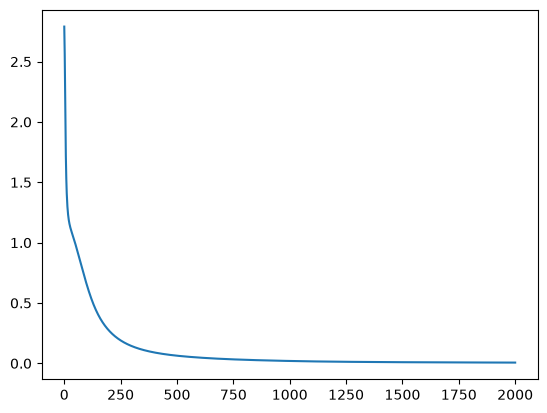

In [1273]:
from matplotlib import pyplot as plt
plt.plot(np.arange(0, epohi + 1), bigerrors)

In [1274]:
print(table)
showwesa()
print(aksonsall)

   id  class         y       err
0   0      0  0.045387 -0.045387
1   1      0  0.041723 -0.041723
2   2      1  0.965099  0.034901
3   3      1  0.980594  0.019406
4   4      0  0.030798 -0.030798
0.4586778403952112
-0.5474268005848391
0.16029084953503214
0.22109335858317114
-0.9560936051026743
0.5743466892877718
-0.5857660604495356
0.3736901795686207
-0.3643514786060425
-0.04001026921536051
-0.6926562678547981
-0.0780638147602839
0.855732504090571
-1.3680011639521281
-0.8583212509778986
-1.077764456202123
-0.4501577942323192
0.7156988763185763
0.5003987586257466
-0.8642036679191508
-1.4585521859457935
0.008569227192703983
-0.11726127411159178
0.9370189556991444
0.6269702991934578
-0.7203455999746898
1.6513010549922158
-1.1099614433668596
2.985226518497908
0.8662734261688421
0.1001152027577239
0.09222715173469087
0.84872842082297
-0.8284235516450471
0.044371855432771
-0.011805944053327133
-0.007842579165246612
-0.7944396115812851
0.8433309207117434
-0.26412541106305
-0.183723398061782

In [1275]:
outputneiron.getvalue = getvaluePOROG
getBIGerror()
print(table)
showwesa()

   id  class  y err
0   0      0  0   0
1   1      0  0   0
2   2      1  1   0
3   3      1  1   0
4   4      0  0   0
0.4586778403952112
-0.5474268005848391
0.16029084953503214
0.22109335858317114
-0.9560936051026743
0.5743466892877718
-0.5857660604495356
0.3736901795686207
-0.3643514786060425
-0.04001026921536051
-0.6926562678547981
-0.0780638147602839
0.855732504090571
-1.3680011639521281
-0.8583212509778986
-1.077764456202123
-0.4501577942323192
0.7156988763185763
0.5003987586257466
-0.8642036679191508
-1.4585521859457935
0.008569227192703983
-0.11726127411159178
0.9370189556991444
0.6269702991934578
-0.7203455999746898
1.6513010549922158
-1.1099614433668596
2.985226518497908
0.8662734261688421
0.1001152027577239
0.09222715173469087
0.84872842082297
-0.8284235516450471
0.044371855432771
-0.011805944053327133
-0.007842579165246612
-0.7944396115812851
0.8433309207117434
-0.26412541106305
-0.18372339806178295
0.3829986228356417
0.7147458778543196
0.09377039169483203
0.237324664370790